# 3. Embed-and-pool classifiers for PAWS-Wiki

In this notebook we build paraphrase classifiers that **embed** every token with a pretrained word embedding, **pool** the token vectors of each sentence into one vector, and classify the pair with an MLP. We answer the two questions of exercise 3:

1. **Which design choices have a meaningful impact on classification performance?** We study the pooling function, how the two sentence vectors are combined, the embeddings (pretrained or not, frozen or trainable, fastText or GloVe, dimension), the classifier architecture and the optimisation parameters.
2. **Is this better than what we achieved last week, that is, did pretrained embeddings add to our design?** We compare fold by fold with the Part 1 models (same folds) and with the same architecture trained without pretrained embeddings.


## 1. Setup

In [5]:
import sys
import copy
import json
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import nltk
from torch.nn.utils.rnn import pad_sequence
from sklearn.metrics import roc_auc_score
from IPython.display import display

sys.path.append(str(Path("..").resolve()))
from src import experiment, bayes_rope
from src import embed_pool as ep
from src.dataset import load_paws, paws_pairs
from src.part2_utils import BasicTokenizer, build_vocab, PAD, UNK
from src.figures import save_figure, save_table

nltk.download("punkt_tab", quiet=True)

SEED = 0            # seed of the folds (the same as in Part 1) and of the default runs
NUM_FOLDS = 5
ROPE = 0.01         # differences below one accuracy point count as a tie (as in Part 1)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(4)   # faster than all cores for these small models on CPU (measured)

RESULTS = Path("results/embed_pool")      # one folder per configuration (config.json + cv.pkl)
CACHE = RESULTS / "_cache"                # token ids (not in git, rebuilt automatically)
IMAGES = Path("images/embed_pool")
TABLES = Path("tables/embed_pool")
PART1 = Path("../part1/results_strict")
for p in (RESULTS, CACHE, IMAGES, TABLES):
    p.mkdir(parents=True, exist_ok=True)
print("PyTorch device:", DEVICE)

PyTorch device: cpu


## 2. Data, folds, tokenizer and embeddings

### 2.1 Cross-validation folds

To make the comparison with Part 1 meaningful, we apply the same training-data filtering and reconstruct the same five grouped folds using seed 0. Grouping by unordered sentence pair prevents a pair and its reversed version from appearing on opposite sides of a fold. We verify that the fold sizes and label counts match the stored Part 1 diagnostics. This check supports comparability, although matching summary statistics alone does not prove identity of every pair index.

In [6]:
dataset = load_paws(remove_conflicts=True)
train_pairs = paws_pairs(dataset["train"])
folds = experiment.cross_validation_split(train_pairs, k=NUM_FOLDS, seed=SEED)

fold_report = experiment.fold_diagnostics(folds)
display(fold_report)
assert (fold_report["overlapping_pairs"] == 0).all()

part1_report = pd.read_csv(PART1 / "fold_diagnostics.csv")
cols = ["fold", "train", "validation", "label0", "label1"]
assert fold_report[cols].equals(part1_report[cols]), "The folds differ from the Part 1 folds"
print("Same folds as in Part 1.")

Removed 63 examples from 31 conflicting pairs.
Training examples remaining: 49,338


,fold,train,validation,label0,label1,label1_ratio,overlapping_pairs,validation_pairs_with_shared_sentence
0,0,39470,9868,5508,4360,0.441832,0,9418
1,1,39470,9868,5508,4360,0.441832,0,9474
2,2,39470,9868,5509,4359,0.441731,0,9436
3,3,39471,9867,5508,4359,0.441776,0,9442
4,4,39471,9867,5508,4359,0.441776,0,9390


Same folds as in Part 1.


### 2.2 Tokenization and embedding matrices

We use the tokenizer from Exercise 1: lowercasing is enabled, while punctuation and stopwords are retained. We rebuild its vocabulary and load the 300-dimensional fastText and GloVe matrices created earlier. Each row of these matrices must correspond to the same token ID as in the original vocabulary; matching matrix shapes alone does not guarantee alignment.

The vocabulary is built from the full PAWS training split before constructing the cross-validation folds. This does not use validation labels, but it means that the vocabulary can contain tokens seen only in a particular fold's validation subset. The same vocabulary is used for all methods so that the comparisons remain consistent. This is a transductive vocabulary choice and should be distinguished from fitting a new vocabulary inside each training fold.

In [7]:
tokenizer = BasicTokenizer(lowercase=True, remove_punct=False, remove_stopwords=False)
vocab, counts = build_vocab(
    list(dataset["train"]["sentence1"]) + list(dataset["train"]["sentence2"]), tokenizer=tokenizer)
tokenizer.vocab = vocab
PAD_ID, UNK_ID = vocab.index(PAD), vocab.index(UNK)

E_ft = torch.load("results/E_ft.pt")
E_glove = torch.load("results/E_glove.pt")
assert E_ft.shape == E_glove.shape == (len(vocab), 300), "Matrices are not aligned with the vocabulary"
assert torch.all(E_ft[PAD_ID] == 0)
print(f"Vocabulary: {len(vocab):,} types (incl. {PAD} and {UNK}); embeddings: {tuple(E_ft.shape)}")

# Scale of the two pretrained spaces: it matters when they are fed to the same MLP
scale = pd.DataFrame({
    "per-dimension std": [E_ft[2:].std().item(), E_glove[2:].std().item()],
    "mean vector norm": [E_ft[2:].norm(dim=1).mean().item(), E_glove[2:].norm(dim=1).mean().item()],
}, index=["fastText", "GloVe"])
display(scale)

Vocabulary: 31,479 types (incl. <pad> and <unk>); embeddings: (31479, 300)


,per-dimension std,mean vector norm
fastText,0.062672,1.027236
GloVe,0.358503,5.931219


Each pair is converted to token IDs once and cached. Fold-specific training and validation examples are then selected using the corresponding indices. This avoids repeated tokenization and ensures that the tested configurations receive the same token sequences. If the tokenizer or vocabulary changes, the token-ID cache must be regenerated.

In [8]:
ids_file = CACHE / "train_token_ids.pkl"
if ids_file.exists():
    with ids_file.open("rb") as f:
        all_ids = pickle.load(f)
else:
    all_ids = ep.tokenize_pairs(train_pairs, tokenizer)
    with ids_file.open("wb") as f:
        pickle.dump(all_ids, f)
assert len(all_ids) == len(train_pairs)

fold_ids = {
    fold: {part: [all_ids[i] for i in split[f"{part}_ids"]] for part in ("training", "validation")}
    for fold, split in folds.items()
}
for fold, split in folds.items():
    assert [y for _, y in fold_ids[fold]["validation"]] == [y for _, y in split["validation"]]

lengths = pd.Series([len(a) for (a, b), _ in all_ids] + [len(b) for (a, b), _ in all_ids])
print("Tokens per sentence:", lengths.describe().round(1).to_dict())

Tokens per sentence: {'count': 98676.0, 'mean': 21.3, 'std': 5.5, 'min': 2.0, '25%': 17.0, '50%': 21.0, '75%': 26.0, 'max': 37.0}


### 2.3 Part 1 baselines

We reuse the fold-level accuracy of the majority-class baseline, the best cross-validated n-gram MLP, and the final bigram logistic-regression classifier from Part 1. Their mean accuracies are 55.82%, 58.49%, and 58.81%, respectively. Because the same evaluation folds are used, model differences can be examined as paired differences across folds.

In [9]:
def load_part1_scores(path):
    with open(path, "rb") as f:
        res = pickle.load(f)
    return res

SCORES = {}     
PREDS = {}       

majority = {}
for fold, split in folds.items():
    train_y = np.array([y for _, y in split["training"]])
    val_y = np.array([y for _, y in split["validation"]])
    majority[fold] = np.mean(val_y == np.bincount(train_y).argmax())
SCORES["P1 majority"] = pd.Series(majority)

for alias, path in {
    "P1 best MLP (n-grams)": PART1 / "models/mlp_NGram_dropout0.3_hidden_dim64/cv.pkl",
    "P1 final (logistic, bigrams)": PART1 / "final_ngram_ablation/bigrams_only_8k/models/logistic_NGram_C0.01/cv.pkl",
}.items():
    res = load_part1_scores(path)
    SCORES[alias] = pd.Series(dict(res["accuracies"]))
    PREDS[alias] = res["predictions"]

P1_REFS = ["P1 majority", "P1 best MLP (n-grams)", "P1 final (logistic, bigrams)"]
display(pd.DataFrame({k: SCORES[k] for k in P1_REFS}).agg(["mean", "std"]).T.round(4))

,mean,std
P1 majority,0.5582,0.0000
P1 best MLP (n-grams),0.5849,0.0053
"P1 final (logistic, bigrams)",0.5881,0.0044


## 3. What Information Does Embed-and-Pool Preserve?

Mean and sum pooling aggregate token embeddings without retaining their positions. Max pooling is also order-invariant. Consequently, two sentences containing exactly the same multiset of tokens produce the same pooled vector, even if reordering the words changes their meaning. This is especially relevant to PAWS, where high lexical overlap does not necessarily imply paraphrase equivalence.

### 3.1 A word-order counterexample

We select a non-paraphrase pair whose sentences contain the same token IDs in a different order and compare their mean-pooled fastText vectors.

In [6]:
encoder = ep.PoolEncoder(E_ft, pooling="mean")

def pooled(seqs, enc=encoder, batch=2048):
    out = []
    with torch.no_grad():
        for i in range(0, len(seqs), batch):
            x = pad_sequence([torch.tensor(s) for s in seqs[i:i + batch]], batch_first=True, padding_value=PAD_ID)
            out.append(enc(x))
    return torch.cat(out)

i = next(j for j, ((a, b), y) in enumerate(all_ids) if y == 0 and sorted(a) == sorted(b) and a != b)
(s1, s2), y = train_pairs[i]
u, v = pooled([all_ids[i][0][0], all_ids[i][0][1]])
print("Sentence 1:", s1)
print("Sentence 2:", s2)
print("Label:", "paraphrase" if y else "not a paraphrase")
print(f"cos(u, v) = {F.cosine_similarity(u, v, dim=0):.6f}   max |u - v| = {(u - v).abs().max():.2e}")

Sentence 1: The Soviet Union maintained an embassy in Oslo and a consulate in Barentsburg , while Norway maintained a message in Moscow .
Sentence 2: The Soviet Union maintained an embassy in Moscow and a consulate in Barentsburg , while Norway maintained a message in Oslo .
Label: not a paraphrase
cos(u, v) = 1.000000   max |u - v| = 1.49e-08


### 3.2 Is cosine similarity alone informative?

We also examine the cosine similarity between the two mean-pooled sentence representations. This is not an evaluation of the trained classifier: it tests whether one simple similarity score can discriminate paraphrases from non-paraphrases. We compare its distribution across labels and calculate its ROC AUC.

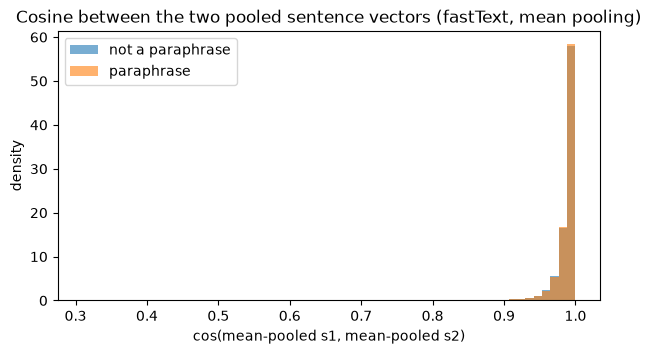

Mean cosine: not paraphrase 0.9879, paraphrase 0.9881
ROC AUC of the cosine alone: 0.489
Pairs with cosine > 0.999: 9.5%


In [7]:
U = pooled([a for (a, b), _ in all_ids])
V = pooled([b for (a, b), _ in all_ids])
cos = F.cosine_similarity(U, V).numpy()
labels = np.array([y for _, y in all_ids])

fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(min(cos.min(), 0.8), 1.0, 60)
for lab, name in [(0, "not a paraphrase"), (1, "paraphrase")]:
    ax.hist(cos[labels == lab], bins=bins, alpha=0.6, density=True, label=name)
ax.set(xlabel="cos(mean-pooled s1, mean-pooled s2)", ylabel="density",
       title="Cosine between the two pooled sentence vectors (fastText, mean pooling)")
ax.legend()
save_figure(fig, IMAGES / "cosine_by_label.png")
plt.show()

print(f"Mean cosine: not paraphrase {cos[labels == 0].mean():.4f}, paraphrase {cos[labels == 1].mean():.4f}")
print(f"ROC AUC of the cosine alone: {roc_auc_score(labels, cos):.3f}")
print(f"Pairs with cosine > 0.999: {np.mean(cos > 0.999):.1%}")

In the selected non-paraphrase example, the pooled vectors are numerically identical (cosine similarity 1.000000, maximum absolute difference approximately 1.49 × 10⁻⁸) despite the different meaning introduced by the word swap. Across the training pairs, the mean cosine similarity is 0.9879 for non-paraphrases and 0.9881 for paraphrases. Cosine similarity alone achieves an ROC AUC of 0.489, close to chance, and 9.5% of pairs have cosine similarity above 0.999.

These results show that the two classes are difficult to distinguish using cosine similarity alone. They do not imply that an MLP using the full pooled pair features cannot learn useful predictive patterns. However, information about word order has been discarded before classification, and the MLP cannot recover that missing information.

## 4. Experimental protocol

**Model.** The two sentences pass through a shared embedding-and-pooling encoder. Their representations, u and v, are combined into pair features and passed to an MLP predicting two classes with a log-softmax output. Frozen embeddings remain fixed; trainable embeddings are updated together with the classifier.

**Training.** We use Adam and negative log-likelihood loss. For each outer cross-validation fold, we reserve 10% of its training portion as an inner development set for early stopping. This inner split groups unordered sentence pairs, and early stopping selects the epoch with the lowest development loss (patience = 3). The outer validation fold is not used for gradient updates or early stopping.

**Evaluation.** We report mean accuracy, its standard deviation across five folds, and macro-F1. Starting from a reference configuration, we vary a small number of factors at each stage, selecting the highest mean cross-validation accuracy to carry forward. This is a computationally manageable sequential search, not an exhaustive grid or proof of global optimality.

| Stage | Question | Values |
|---|---|---|
| A | pooling and pair representation | mean vs. sum / concatenation vs. absolute difference + elementwise product |
| B | embeddings and dimensionality | Frozen/trainable fastText 300d, frozen/trainable random 300d, and frozen fastText reduced to 100d by PCA |
| C | classifier capacity | No hidden layer, 128 or 256 units, two 128-unit layers, and dropout 0.1 vs 0.3 |
| D | Optimization | Learning rate 1e-3 vs 1e-4; batch size 64 vs 256 |
| Additional controls | Relation to Part 1 | Earlier MLP and logistic classifiers applied to fixed pooled features |
| Robustness | Sensitivity to training randomness | Final configuration evaluated with seeds 0, 1, and 2 |

We use the Bayesian correlated t-test from Part 1 with a ROPE of ±1 percentage point of accuracy to distinguish practically meaningful differences from small differences. These comparisons are exploratory, particularly when the compared model was chosen using the same folds. Repeating the final configuration across three seeds describes initialization sensitivity but does not eliminate model-selection bias.

In [7]:
EMB_STD = float(E_ft[2:].std())   # random embeddings get the same scale as fastText
_matrices = {}

def embedding_matrix(emb, dim=300, seed=0):
    # The embedding matrix of a configuration (cached).
    key = (emb, dim, seed if emb == "random" else None)
    if key not in _matrices:
        if emb == "fasttext":
            if dim == 300:
                M = E_ft
            else:
                M, var = ep.pca_embeddings(E_ft, dim, PAD_ID, UNK_ID)
                print(f"PCA fastText to {dim} dims keeps {var:.1%} of the variance")
        elif emb == "glove":
            assert dim == 300
            M = E_glove
        elif emb == "random":
            M = ep.random_embeddings(len(vocab), dim, EMB_STD, PAD_ID, seed=seed)
        else:
            raise ValueError(emb)
        _matrices[key] = M
    return _matrices[key]


BASE = {
    "emb": "fasttext", "dim": 300,
    "model": {"pooling": "mean", "pair_mode": "full", "freeze": True,
              "hidden_sizes": [128], "dropout": 0.1, "activation": "relu"},
    "opt": dict(ep.DEFAULT_OPT),
}
CFGS, RUNS = {}, {}


def variant(cfg, emb=None, dim=None, model=None, opt=None):
    new = copy.deepcopy(cfg)
    if emb is not None:
        new["emb"] = emb
    if dim is not None:
        new["dim"] = dim
    new["model"].update(model or {})
    new["opt"].update(opt or {})
    return new


def run(name, cfg, seed=0):
    # Cross-validate one configuration (or load it if it is already finished).
    E = embedding_matrix(cfg["emb"], cfg["dim"], seed)
    res = ep.run_cv(name, folds, fold_ids, E, cfg["model"], cfg["opt"], seed=seed,
                    pad_id=PAD_ID, device=DEVICE, results_dir=RESULTS,
                    extra_config={"emb": cfg["emb"], "dim": cfg["dim"]})
    CFGS[name], RUNS[name] = cfg, res
    SCORES[name] = pd.Series(dict(res["accuracies"]))
    PREDS[name] = res["predictions"]
    return res


def summarize(names, save_as=None):
    rows = []
    for n in names:
        if n in RUNS:
            res, cfg = RUNS[n], CFGS[n]
            saved = json.loads((RESULTS / n / "config.json").read_text())
            best = list(res["best_epoch"].values())
            n_ep = [len(h) for h in res["history"].values()]
            rows.append({
                "system": n,
                "acc mean": SCORES[n].mean(), "acc std": SCORES[n].std(),
                "macro-F1": np.mean(list(res["macro_f1"].values())),
                "Δ vs P1 best MLP": SCORES[n].mean() - SCORES["P1 best MLP (n-grams)"].mean(),
                "trainable params": saved["trainable_params"],
                "best epoch (mean)": np.mean(best),
                "hit max epochs": any(e == cfg["opt"]["num_epochs"] for e in n_ep),
            })
        else:   # Part 1 references
            rows.append({"system": n, "acc mean": SCORES[n].mean(), "acc std": SCORES[n].std()})
    df = pd.DataFrame(rows).set_index("system")
    if save_as:
        save_table(df, TABLES / f"{save_as}.csv")
    return df.style.format(precision=4, thousands=",")


def best_of(names):
    # Configuration with the highest mean CV accuracy (Part 2 systems only).
    return max([n for n in names if n in RUNS], key=lambda n: SCORES[n].mean())


def plot_folds(names, title, save_as=None, refs=("P1 majority", "P1 best MLP (n-grams)")):
    # Per-fold accuracy (points) and its spread (box) for each system.
    fig, ax = plt.subplots(figsize=(max(6, 0.9 * len(names) + 2), 4))
    rng = np.random.default_rng(0)
    for i, n in enumerate(names):
        acc = SCORES[n].values
        ax.boxplot(acc, positions=[i], widths=0.5, showfliers=False)
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(acc)), acc, s=16, alpha=0.75, zorder=3)
    for ref, style in zip(refs, [":", "--"]):
        ax.axhline(SCORES[ref].mean(), ls=style, color="gray", lw=1, label=f"{ref} ({SCORES[ref].mean():.3f})")
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels(names, rotation=35, ha="right", fontsize=8)
    ax.set(ylabel="validation accuracy (5 folds)", title=title)
    ax.legend(fontsize=8, loc="best")
    fig.tight_layout()
    if save_as:
        save_figure(fig, IMAGES / f"{save_as}.png")
    plt.show()


def compare(pairs, save_as=None, plot=False):
    # Bayesian correlated t-test (Part 1 code) on per-fold accuracies, A - B.
    names = list(dict.fromkeys(n for p in pairs for n in p))
    wide = pd.DataFrame({n: SCORES[n] for n in names})
    table, posteriors = bayes_rope.compare_models(wide, k=NUM_FOLDS, rope=ROPE, pairs=pairs)
    if save_as:
        save_table(table, TABLES / f"{save_as}.csv")
    if plot:
        fig = bayes_rope.plot_posteriors(posteriors, rope=ROPE)
        if save_as:
            save_figure(fig, IMAGES / f"{save_as}.png")
        plt.show()
    return table.style.format(precision=3)

### 5. Stage A — Pooling and Pair Representation
First, we investigate how sentence representations are constructed and combined while keeping the fastText 300d embeddings frozen and the classifier fixed at one hidden layer of 128 ReLU units (dropout 0.1).

We compare two pooling operations—mean and sum—and two pair representations: concatenation, [u, v], and absolute difference plus elementwise product, [|u − v|, u ⊙ v]. This gives four configurations. Both pair representations have 600 input features, so they use the same number of classifier parameters under this fixed architecture. Neither pooling operation preserves word order.

We select the configuration with the highest mean cross-validation accuracy, then compare it against alternatives that differ in only one factor.

Experiment: mean, concat
▶ A_mean_concat: training 5 folds | model {'pooling': 'mean', 'pair_mode': 'concat', 'freeze': True, 'hidden_sizes': [128], 'dropout': 0.1, 'activation': 'relu'} | lr 0.001, batch 64, max 30 epochs, seed 0


[A_mean_concat | fold 1/5] epoch 1/30:   0%|          | 0/556 [00:00<?, ?it/s]

    [A_mean_concat | fold 1/5] epoch  1/30  train loss 0.6845 acc 0.5618 | dev loss 0.6794 acc 0.5747  (164s)  *


[A_mean_concat | fold 1/5] epoch 2/30:   0%|          | 0/556 [00:00<?, ?it/s]

    [A_mean_concat | fold 1/5] epoch  2/30  train loss 0.6809 acc 0.5697 | dev loss 0.6759 acc 0.5777  (194s)  *


[A_mean_concat | fold 1/5] epoch 3/30:   0%|          | 0/556 [00:00<?, ?it/s]

... (496 outputs left out)

    [A_sum_diff_prod | fold 5/5] epoch 13/30  train loss 0.6663 acc 0.5798 | dev loss 0.6729 acc 0.5678  (178s)


[A_sum_diff_prod | fold 5/5] epoch 14/30:   0%|          | 0/556 [00:00<?, ?it/s]

    [A_sum_diff_prod | fold 5/5] epoch 14/30  train loss 0.6647 acc 0.5845 | dev loss 0.6708 acc 0.5718  (173s)
    [A_sum_diff_prod | fold 5/5] early stop: no dev improvement for 3 epochs
  → fold 5/5: validation acc 0.5778 (best epoch 11 of 14) | 44.1 min so far, ~0.0 min left for A_sum_diff_prod
[A_sum_diff_prod] mean acc = 0.5740 ± 0.0028 (44.12 min)


,acc mean,acc std,macro-F1,Δ vs P1 best MLP,trainable params,best epoch (mean),hit max epochs
system,,,,,,,
A_mean_concat,0.5758,0.0021,0.4622,-0.0091,"77,186.0000",6.6000,False
A_mean_diff_prod,0.5675,0.0052,0.4966,-0.0174,"77,186.0000",11.6000,False
A_sum_concat,0.5790,0.0028,0.4520,-0.0059,"77,186.0000",8.8000,False
A_sum_diff_prod,0.5740,0.0031,0.4457,-0.0109,"77,186.0000",8.0000,False
P1 majority,0.5582,0.0000,nan,nan,nan,nan,nan
P1 best MLP (n-grams),0.5849,0.0053,nan,nan,nan,nan,nan
"P1 final (logistic, bigrams)",0.5881,0.0044,nan,nan,nan,nan,nan


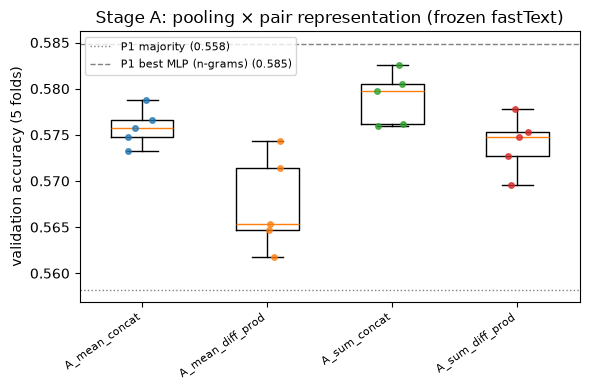

Best stage A configuration: A_sum_concat


In [9]:
stage_a = []
for pooling in ["mean", "sum"]:
    for pair_mode in ["concat", "diff_prod"]:
        print(f"Experiment: {pooling}, {pair_mode}")
        name = f"A_{pooling}_{pair_mode}"
        run(name, variant(BASE, model={"pooling": pooling, "pair_mode": pair_mode}))
        stage_a.append(name)

display(summarize(stage_a + P1_REFS, save_as="stage_a"))
plot_folds(stage_a, "Stage A: pooling × pair representation (frozen fastText)", save_as="stage_a")
BEST_A = best_of(stage_a)
print("Best stage A configuration:", BEST_A)

In [10]:
# Is the best stage A configuration really different from the default (mean, full)
# and from the alternatives that differ in one factor only?
best_pool, best_pair = BEST_A.split("_", 2)[1:]
pairs = [(BEST_A, n) for n in stage_a if n != BEST_A
         and (n.startswith(f"A_{best_pool}_") or n.endswith(f"_{best_pair}"))]
pairs.append((BEST_A, "P1 majority"))
display(compare(pairs, save_as="stage_a_bayes"))

,A,B,mean_diff,HDI95_low,HDI95_high,P(A better),P(ROPE),P(B better),decision
0,A_sum_concat,A_mean_concat,0.003,-0.000,0.007,0.003,0.997,0.000,equivalent
1,A_sum_concat,A_sum_diff_prod,0.005,0.001,0.009,0.018,0.982,0.000,equivalent
2,A_sum_concat,P1 majority,0.021,0.015,0.026,0.998,0.002,0.000,A_sum_concat better


**Stage A results**: Sum + concatenation achieves the highest mean accuracy (57.90%), followed by mean + concatenation (57.58%) and sum + difference/product (57.40%). Mean + difference/product achieves 56.75%, but it has the highest macro-F1 (0.4966), illustrating that the accuracy ranking does not capture every class-level trade-off.

The Bayesian comparisons assign probabilities of 0.997 and 0.982 to practical equivalence between the winner and, respectively, mean + concatenation and sum + difference/product. Therefore, although A_sum_concat is selected for the next stage, the tested pooling and pair-composition choices show no clear practically meaningful advantage over their closest alternatives under the chosen ROPE. It also exceeds the majority baseline (55.82%), while remaining below the best Part 1 MLP (58.49%).

## 6. Stage B — Embedding Initialization, Fine-Tuning, and Size
We now keep the architecture selected in Stage A (sum pooling, concatenation, 128 hidden units) and change the embedding layer. The aim is to separate three questions:
1. Does pretraining help? Compare fastText against random embeddings with the same dimensionality and freeze setting: fastText frozen versus random frozen, and fastText trainable versus random trainable.
2. Does fine-tuning help? Compare frozen and trainable fastText embeddings, and frozen and trainable random embeddings.
3. Does embedding size matter? Compare frozen fastText 300d against a 100d PCA projection of the same pretrained space. PCA retains the directions of greatest variance; this tests compression, not separately pretrained 100d fastText embeddings.
The randomly initialized vectors are scaled to match the overall standard deviation of fastText. When embeddings are trainable, both the embeddings and MLP are optimized; when frozen, only the MLP is trained. All reported comparisons use the same five folds.

In [11]:
cfg_a = CFGS[BEST_A]

B_SPECS = {
    "B_fasttext_trainable": dict(
        emb="fasttext", dim=300,
        model={"freeze": False}
    ),
    "B_random_frozen_300": dict(
        emb="random", dim=300,
        model={"freeze": True}
    ),
    "B_random_trainable_300": dict(
        emb="random", dim=300,
        model={"freeze": False}
    ),
    "B_fasttext_pca100_frozen": dict(
        emb="fasttext", dim=100,
        model={"freeze": True}
    ),
}

for name, spec in B_SPECS.items():
    print(f"Running: {name}")
    run(name, variant(cfg_a, **spec))

stage_b = [BEST_A] + list(B_SPECS)

display(summarize(stage_b + P1_REFS))

BEST_B = best_of(stage_b)
print("Best Stage B:", BEST_B)

Running: B_fasttext_trainable
▶ B_fasttext_trainable: training 5 folds | model {'pooling': 'sum', 'pair_mode': 'concat', 'freeze': False, 'hidden_sizes': [128], 'dropout': 0.1, 'activation': 'relu'} | lr 0.001, batch 64, max 30 epochs, seed 0


[B_fasttext_trainable | fold 1/5] epoch 1/30:   0%|          | 0/556 [00:00<?, ?it/s]

    [B_fasttext_trainable | fold 1/5] epoch  1/30  train loss 0.6772 acc 0.5769 | dev loss 0.6564 acc 0.6053  (318s)  *


[B_fasttext_trainable | fold 1/5] epoch 2/30:   0%|          | 0/556 [00:00<?, ?it/s]

    [B_fasttext_trainable | fold 1/5] epoch  2/30  train loss 0.6465 acc 0.6113 | dev loss 0.6599 acc 0.6076  (166s)


[B_fasttext_trainable | fold 1/5] epoch 3/30:   0%|          | 0/556 [00:00<?, ?it/s]

... (201 outputs left out)

[B_fasttext_pca100_frozen | fold 5/5] epoch 5/30:   0%|          | 0/556 [00:00<?, ?it/s]

    [B_fasttext_pca100_frozen | fold 5/5] epoch  5/30  train loss 0.6762 acc 0.5779 | dev loss 0.6844 acc 0.5678  (63s)
    [B_fasttext_pca100_frozen | fold 5/5] early stop: no dev improvement for 3 epochs
  → fold 5/5: validation acc 0.5736 (best epoch 2 of 5) | 12.8 min so far, ~0.0 min left for B_fasttext_pca100_frozen
[B_fasttext_pca100_frozen] mean acc = 0.5723 ± 0.0020 (12.8 min)


,acc mean,acc std,macro-F1,Δ vs P1 best MLP,trainable params,best epoch (mean),hit max epochs
system,,,,,,,
A_sum_concat,0.5790,0.0028,0.4520,-0.0059,"77,186.0000",8.8000,False
B_fasttext_trainable,0.5955,0.0058,0.4688,0.0106,"9,520,886.0000",0.2000,False
B_random_frozen_300,0.5734,0.0043,0.4774,-0.0115,"77,186.0000",1.4000,False
B_random_trainable_300,0.5978,0.0020,0.4728,0.0129,"9,520,886.0000",0.0000,False
B_fasttext_pca100_frozen,0.5723,0.0022,0.4567,-0.0126,"25,986.0000",3.2000,False
P1 majority,0.5582,0.0000,nan,nan,nan,nan,nan
P1 best MLP (n-grams),0.5849,0.0053,nan,nan,nan,nan,nan
"P1 final (logistic, bigrams)",0.5881,0.0044,nan,nan,nan,nan,nan


Best Stage B: B_random_trainable_300


**Stage B results**: The strongest configuration is random embeddings, 300 dimensions, trainable (59.78% accuracy), closely followed by trainable fastText 300d (59.55%). Frozen fastText reaches 57.90%, while frozen random embeddings reach 57.34%. Reducing frozen fastText to 100 dimensions with PCA (retaining 59.8% of the original embedding variance) yields 57.23%.

Allowing the embeddings to be updated is associated with a larger accuracy gain than changing the embedding initialization in the experiments tested. Crucially, fastText pretraining does not outperform random initialization when both embeddings are trainable: the observed difference is only −0.23 percentage points (fastText minus random), and the final paired Bayesian comparison assigns 0.940 posterior probability to practical equivalence within our ROPE. Frozen fastText is slightly ahead of frozen random embeddings (+0.56 points), but this is also a small difference.

We therefore select B_random_trainable_300 for Stage C. This result does not show that pretrained embeddings are useless in general; it shows that they provide no clear advantage in these particular settings and folds. The benefits of trainability should not be confused with the benefits of pretraining.

### 6.1 Reusing the Part 1 MLP with Pooled Embeddings

To compare the new representation more directly against our earlier approach, we reuse the MLP model family and training hyperparameters from Part 1, but replace its n-gram feature input with fixed mean-pooled word embeddings. The embeddings are not fine-tuned in this experiment. We construct a 600-dimensional representation for each pair using [|u − v|, u ⊙ v] and retrain the MLP from scratch on each fold.

We test fastText, GloVe, and randomly initialized vectors. The random-embedding control helps distinguish the value of information learned during pretraining from the effect of simply using a dense pooled representation.

This is a related but not perfectly controlled replacement of the Part 1 input: changing from sparse n-gram features to 600-dimensional dense features also changes the input dimensionality and the number of parameters in the first MLP layer. Therefore, any performance difference cannot be attributed exclusively to pretraining.

Part 1 MLP hyper-parameters: {'activation': 'relu', 'batch_size': 64, 'device': 'cpu', 'dropout': 0.3, 'hidden_dim': 64, 'learning_rate': 0.0001, 'num_epochs': 20, 'num_hidden_layers': 1, 'patience': 2, 'seed': 0, 'weight_decay': 0.0001}
▶ P1MLP_fasttext: Part 1 MLP on 5 folds (600 input features)
    [P1MLP_fasttext | fold 1/5] epoch  1/20  train loss 0.7269 | dev loss 0.6914 acc 0.5551  *
    [P1MLP_fasttext | fold 1/5] epoch  2/20  train loss 0.7007 | dev loss 0.6851 acc 0.5645  *
    [P1MLP_fasttext | fold 1/5] epoch  3/20  train loss 0.6887 | dev loss 0.6823 acc 0.5714  *
    [P1MLP_fasttext | fold 1/5] epoch  4/20  train loss 0.6822 | dev loss 0.6796 acc 0.5726  *
    [P1MLP_fasttext | fold 1/5] epoch  5/20  train loss 0.6770 | dev loss 0.6795 acc 0.5734  *
    [P1MLP_fasttext | fold 1/5] epoch  6/20  train loss 0.6746 | dev loss 0.6801 acc 0.5749
    [P1MLP_fasttext | fold 1/5] epoch  7/20  train loss 0.6731 | dev loss 0.6805 acc 0.5670
  → fold 1/5: validation acc 0.5617 (best 

,input,acc mean,acc std,macro-F1,selected epochs (mean)
P1 best MLP (n-grams),"8,000 n-gram counts (Part 1)",0.5849,0.0053,,
P1MLP_fasttext,mean fastText,0.5590,0.0047,0.5007,6.4000
P1MLP_glove,mean GloVe,0.5585,0.0032,0.4982,6.2000
P1MLP_random,mean random (fastText scale),0.5560,0.0066,0.4968,5.4000


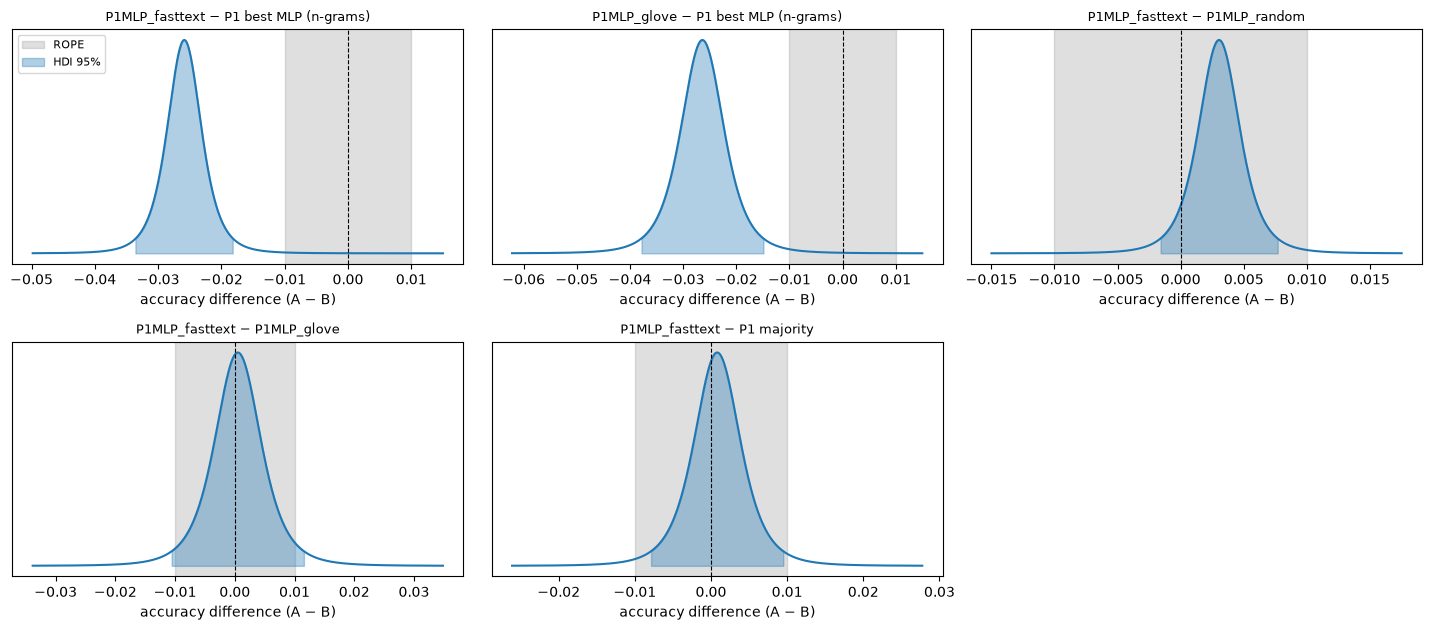

,A,B,mean_diff,HDI95_low,HDI95_high,P(A better),P(ROPE),P(B better),decision
0,P1MLP_fasttext,P1 best MLP (n-grams),-0.026,-0.034,-0.018,0.000,0.002,0.998,P1 best MLP (n-grams) better
1,P1MLP_glove,P1 best MLP (n-grams),-0.026,-0.038,-0.015,0.000,0.008,0.991,P1 best MLP (n-grams) better
2,P1MLP_fasttext,P1MLP_random,0.003,-0.002,0.008,0.007,0.992,0.001,equivalent
3,P1MLP_fasttext,P1MLP_glove,0.001,-0.011,0.012,0.038,0.933,0.029,undecided
4,P1MLP_fasttext,P1 majority,0.001,-0.008,0.009,0.021,0.966,0.013,equivalent


In [8]:
P1_MLP_ARGS = json.loads((PART1 / "models/mlp_NGram_dropout0.3_hidden_dim64/config.json").read_text())["args"]
P1_MLP_ARGS["device"] = DEVICE
print("Part 1 MLP hyper-parameters:", P1_MLP_ARGS)

y_all = np.array([y for _, y in all_ids])
p1mlp = {}
for emb in ["fasttext", "glove", "random"]:
    M = embedding_matrix(emb, 300, seed=0)
    U_emb = ep.pool_sentences([a for (a, b), _ in all_ids], M, "mean", PAD_ID)
    V_emb = ep.pool_sentences([b for (a, b), _ in all_ids], M, "mean", PAD_ID)
    X_emb = ep.pair_features(U_emb, V_emb)            # [|u - v|, u * v], 600 dimensions
    name = f"P1MLP_{emb}"
    res = ep.run_cv_part1_mlp(name, folds, X_emb, y_all, P1_MLP_ARGS, results_dir=RESULTS,
                              extra_config={"emb": emb, "pooling": "mean"}, standardize=True)

    SCORES[name], PREDS[name] = pd.Series(dict(res["accuracies"])), res["predictions"]
    p1mlp[name] = res

p1mlp_table = pd.DataFrame({
    "input": ["8,000 n-gram counts (Part 1)", "mean fastText", "mean GloVe", "mean random (fastText scale)"],
    "acc mean": [SCORES[n].mean() for n in ["P1 best MLP (n-grams)", *p1mlp]],
    "acc std": [SCORES[n].std() for n in ["P1 best MLP (n-grams)", *p1mlp]],
    "macro-F1": [np.nan] + [np.mean(list(r["macro_f1"].values())) for r in p1mlp.values()],
    "selected epochs (mean)": [np.nan] + [np.mean(list(r["selected_epochs"].values())) for r in p1mlp.values()],
}, index=["P1 best MLP (n-grams)", *p1mlp])
display(save_table(p1mlp_table, TABLES / "part1_mlp_on_embeddings.csv").style.format(precision=4, na_rep=""))

display(compare([
    ("P1MLP_fasttext", "P1 best MLP (n-grams)"),   # same classifier: embeddings vs n-gram counts
    ("P1MLP_glove", "P1 best MLP (n-grams)"),
    ("P1MLP_fasttext", "P1MLP_random"),            # same classifier: pretrained vs random vectors
    ("P1MLP_fasttext", "P1MLP_glove"),
    ("P1MLP_fasttext", "P1 majority"),
], save_as="part1_mlp_on_embeddings_bayes", plot=True))

MLP control results. The Part 1 n-gram MLP achieves 58.49% accuracy, while the MLP trained on fixed pooled embeddings reaches 55.90% with fastText, 55.85% with GloVe, and 55.60% with random vectors. Under the paired Bayesian comparison, the Part 1 MLP is favored over both pretrained-feature alternatives, with probabilities above 0.99 of a practically meaningful advantage.

The difference between fastText and random pooled features is only 0.30 percentage points, with 0.992 probability of practical equivalence within the ROPE. Thus, under the reused Part 1 MLP settings, replacing n-gram features with pooled embeddings does not improve accuracy, and the pretrained vectors provide at most a small benefit over random vectors. This complements Stage B: the strongest results come from jointly training embeddings with the classifier, not simply substituting fixed pretrained features.

### 6.2 Logistic Regression on Fixed Pooled Embeddings
As a second control, we apply logistic regression to the same frozen, mean-pooled pair features. We compare pretrained fastText with randomly initialized vectors and the final bigram logistic-regression baseline from Part 1. This checks whether improvements can be obtained by swapping the input representation while using a simple linear classifier. We fit scaling inside each training fold to avoid using validation statistics when estimating preprocessing parameters.

[P1LOG_fasttext] fold 1/5: validation acc 0.5684
[P1LOG_fasttext] fold 2/5: validation acc 0.5563
[P1LOG_fasttext] fold 3/5: validation acc 0.5591
[P1LOG_fasttext] fold 4/5: validation acc 0.5569
[P1LOG_fasttext] fold 5/5: validation acc 0.5606
[P1LOG_random] fold 1/5: validation acc 0.5612
[P1LOG_random] fold 2/5: validation acc 0.5512
[P1LOG_random] fold 3/5: validation acc 0.5577
[P1LOG_random] fold 4/5: validation acc 0.5504
[P1LOG_random] fold 5/5: validation acc 0.5627


,input,acc mean,acc std,macro-F1
"P1 final (logistic, bigrams)","8,000 bigram counts (Part 1)",0.5881,0.0044,
P1LOG_fasttext,mean fastText,0.5603,0.0049,0.5050
P1LOG_random,mean random (fastText scale),0.5566,0.0056,0.4925


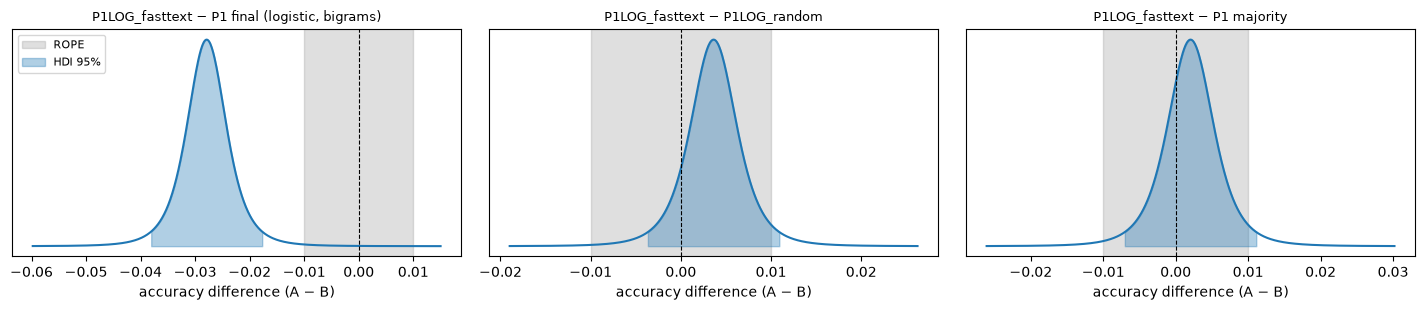

,A,B,mean_diff,HDI95_low,HDI95_high,P(A better),P(ROPE),P(B better),decision
0,P1LOG_fasttext,"P1 final (logistic, bigrams)",-0.028,-0.038,-0.018,0.000,0.004,0.996,"P1 final (logistic, bigrams) better"
1,P1LOG_fasttext,P1LOG_random,0.004,-0.004,0.011,0.036,0.961,0.003,undecided
2,P1LOG_fasttext,P1 majority,0.002,-0.007,0.011,0.036,0.954,0.011,undecided


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

y_all = np.array([y for _, y in all_ids])
p1log = {}

for emb in ["fasttext", "random"]:
    # Embed + mean pool (frozen), then the Part 1 pair representation [|u - v|, u * v]
    M = embedding_matrix(emb, 300)
    U_emb = ep.pool_sentences([a for (a, b), _ in all_ids], M, "mean", PAD_ID)
    V_emb = ep.pool_sentences([b for (a, b), _ in all_ids], M, "mean", PAD_ID)
    X_emb = ep.pair_features(U_emb, V_emb)

    name = f"P1LOG_{emb}"
    acc, f1, preds = {}, {}, {}
    for fold, split in folds.items():
        tr = np.asarray(split["training_ids"])
        va = np.asarray(split["validation_ids"])
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=2000))
        clf.fit(X_emb[tr], y_all[tr])
        preds[fold] = clf.predict(X_emb[va])
        acc[fold] = accuracy_score(y_all[va], preds[fold])
        f1[fold] = f1_score(y_all[va], preds[fold], average="macro")
        print(f"[{name}] fold {fold + 1}/{len(folds)}: validation acc {acc[fold]:.4f}")

    SCORES[name], PREDS[name] = pd.Series(acc), preds
    p1log[name] = np.mean(list(f1.values()))

rows = ["P1 final (logistic, bigrams)", *p1log]
p1log_table = pd.DataFrame({
    "input": ["8,000 bigram counts (Part 1)", "mean fastText", "mean random (fastText scale)"],
    "acc mean": [SCORES[n].mean() for n in rows],
    "acc std": [SCORES[n].std() for n in rows],
    "macro-F1": [np.nan, *p1log.values()],
}, index=rows)
display(save_table(p1log_table, TABLES / "part1_logistic_on_embeddings.csv").style.format(precision=4, na_rep=""))

display(compare([
    ("P1LOG_fasttext", "P1 final (logistic, bigrams)"),   # same classifier: fastText vs bigram counts
    ("P1LOG_fasttext", "P1LOG_random"),                   # same classifier: pretrained vs random vectors
    ("P1LOG_fasttext", "P1 majority"),
], save_as="part1_logistic_on_embeddings_bayes", plot=True))


**Logistic-regression control results**: The fixed pooled-feature classifier obtains 56.03% accuracy with fastText and 55.66% with random embeddings, both below the 58.81% attained by the Part 1 bigram classifier. FastText exceeds random by only 0.37 percentage points, and the Bayesian comparison does not establish a practically meaningful advantage. As with the MLP control, frozen pooled embeddings are not an automatic improvement over the n-gram representation in this setting.

## 7. Stage C: classifier architecture

Using the best embedding setup from Stage B (trainable random 300d, sum pooling, concatenation), we test whether the classifier needs nonlinearity and whether additional capacity improves performance. The reference MLP has one hidden layer of 128 ReLU units and dropout 0.1.

We compare it against a linear output layer (no hidden layer), a wider 256-unit hidden layer, two 128-unit hidden layers, and dropout 0.3 applied to the best size/depth configuration. The classifier is the only architecture component intentionally changed within this stage; the embeddings, pooling, pair features, and main optimization settings remain fixed.

▶ C_hidden_none: training 5 folds | model {'pooling': 'sum', 'pair_mode': 'concat', 'freeze': False, 'hidden_sizes': [], 'dropout': 0.1, 'activation': 'relu'} | lr 0.001, batch 64, max 30 epochs, seed 0


[C_hidden_none | fold 1/5] epoch 1/30:   0%|          | 0/556 [00:00<?, ?it/s]

    [C_hidden_none | fold 1/5] epoch  1/30  train loss 0.6937 acc 0.5428 | dev loss 0.6855 acc 0.5597  (203s)  *


[C_hidden_none | fold 1/5] epoch 2/30:   0%|          | 0/556 [00:00<?, ?it/s]

    [C_hidden_none | fold 1/5] epoch  2/30  train loss 0.6642 acc 0.5975 | dev loss 0.7051 acc 0.5374  (131s)


[C_hidden_none | fold 1/5] epoch 3/30:   0%|          | 0/556 [00:00<?, ?it/s]

... (154 outputs left out)

    [C_dropout0.3 | fold 5/5] epoch  3/30  train loss 0.6280 acc 0.6316 | dev loss 0.7053 acc 0.5951  (151s)


[C_dropout0.3 | fold 5/5] epoch 4/30:   0%|          | 0/556 [00:00<?, ?it/s]

    [C_dropout0.3 | fold 5/5] epoch  4/30  train loss 0.6183 acc 0.6384 | dev loss 0.7411 acc 0.5898  (138s)
    [C_dropout0.3 | fold 5/5] early stop: no dev improvement for 3 epochs
  → fold 5/5: validation acc 0.5940 (best epoch 1 of 4) | 56.4 min so far, ~0.0 min left for C_dropout0.3
[C_dropout0.3] mean acc = 0.5963 ± 0.0025 (56.41 min)


,acc mean,acc std,macro-F1,Δ vs P1 best MLP,trainable params,best epoch (mean),hit max epochs
system,,,,,,,
B_random_trainable_300,0.5978,0.0020,0.4728,0.0129,"9,520,886.0000",0.0000,False
C_hidden_none,0.5470,0.0033,0.5010,-0.0379,"9,444,902.0000",0.0000,False
C_hidden_256,0.5987,0.0014,0.4749,0.0139,"9,598,070.0000",0.0000,False
C_hidden_128x128,0.5970,0.0043,0.4651,0.0121,"9,537,398.0000",0.2000,False
C_dropout0.3,0.5963,0.0028,0.4731,0.0114,"9,598,070.0000",0.0000,False
P1 majority,0.5582,0.0000,nan,nan,nan,nan,nan
P1 best MLP (n-grams),0.5849,0.0053,nan,nan,nan,nan,nan
"P1 final (logistic, bigrams)",0.5881,0.0044,nan,nan,nan,nan,nan


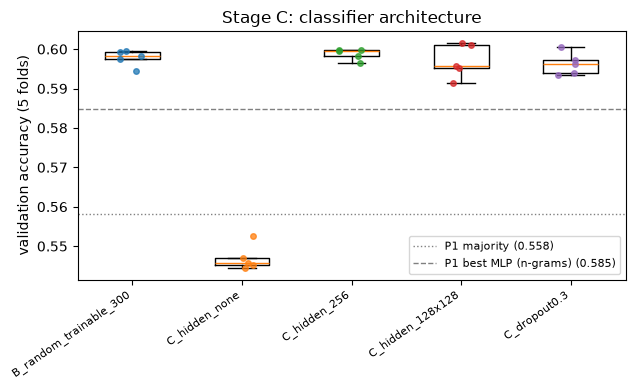

Best stage C configuration: C_hidden_256


,A,B,mean_diff,HDI95_low,HDI95_high,P(A better),P(ROPE),P(B better),decision
0,C_hidden_256,B_random_trainable_300,0.001,-0.001,0.003,0.000,1.000,0.000,equivalent
1,C_hidden_256,C_hidden_none,0.052,0.043,0.060,1.000,0.000,0.000,C_hidden_256 better
2,C_hidden_256,C_hidden_128x128,0.002,-0.004,0.007,0.008,0.989,0.002,equivalent
3,C_hidden_256,C_dropout0.3,0.002,-0.001,0.006,0.002,0.997,0.000,equivalent


In [14]:
cfg_b = CFGS[BEST_B]
c_size = {}
for hidden in [[], [256], [128, 128]]:
    name = "C_hidden_" + ("none" if not hidden else "x".join(map(str, hidden)))
    run(name, variant(cfg_b, model={"hidden_sizes": hidden}))
    c_size[name] = hidden
stage_c1 = [BEST_B] + list(c_size)          # BEST_B has one hidden layer of 128 units
BEST_C1 = best_of(stage_c1)

c_reg = []
for dropout in [0.3]:
    name = f"C_dropout{dropout}"
    run(name, variant(CFGS[BEST_C1], model={"dropout": dropout}))
    c_reg.append(name)

stage_c = stage_c1 + c_reg
display(summarize(stage_c + P1_REFS, save_as="stage_c"))
plot_folds(stage_c, "Stage C: classifier architecture", save_as="stage_c")
BEST_C = best_of(stage_c)
print("Best stage C configuration:", BEST_C)
display(compare([(BEST_C, n) for n in stage_c if n != BEST_C], save_as="stage_c_bayes"))

**Stage C results**: The classifier with no hidden layer obtains 54.70% accuracy, compared with 59.78% for the reference 128-unit MLP. This substantial gap shows that a linear classifier on these concatenated sentence features is insufficient in the tested setting. In contrast, a 256-unit hidden layer achieves 59.87%, two 128-unit layers achieve 59.70%, and increasing dropout to 0.3 yields 59.63%.

The Bayesian comparison indicates that the 256-unit model clearly outperforms the linear alternative, but is practically equivalent to the 128-unit, two-layer, and higher-dropout variants (posterior ROPE probabilities of 1.000, 0.989, and 0.997, respectively). We carry forward C_hidden_256 because it has the highest mean accuracy, while recognizing that its advantage over other nonlinear MLPs is small. The linear baseline's lower accuracy does not imply that all linear classifiers or pair feature representations would perform equally poorly.

## 8. Stage D: optimization

Keeping the architecture selected in Stage C fixed, we test two training choices: a lower learning rate (1e-4 instead of 1e-3) and a larger batch size (256 instead of 64). Adam, weight decay, the maximum number of epochs, and the early-stopping rule remain unchanged.

In [15]:
cfg_c = CFGS[BEST_C]

D_SPECS = {
    "D_lr1e-4":   {"learning_rate": 1e-4},
    "D_batch256": {"batch_size": 256},
}

for name, opt in D_SPECS.items():
    run(name, variant(cfg_c, opt=opt))

stage_d = [BEST_C] + list(D_SPECS)

display(summarize(stage_d + P1_REFS, save_as="stage_d"))

FINAL = best_of(stage_d)
print("Final configuration:", FINAL)

display(compare([(FINAL, n) for n in stage_d if n != FINAL], save_as="stage_d_bayes"))


▶ D_lr1e-4: training 5 folds | model {'pooling': 'sum', 'pair_mode': 'concat', 'freeze': False, 'hidden_sizes': [256], 'dropout': 0.1, 'activation': 'relu'} | lr 0.0001, batch 64, max 30 epochs, seed 0


[D_lr1e-4 | fold 1/5] epoch 1/30:   0%|          | 0/556 [00:00<?, ?it/s]

    [D_lr1e-4 | fold 1/5] epoch  1/30  train loss 0.6850 acc 0.5619 | dev loss 0.6799 acc 0.5800  (131s)  *


[D_lr1e-4 | fold 1/5] epoch 2/30:   0%|          | 0/556 [00:00<?, ?it/s]

    [D_lr1e-4 | fold 1/5] epoch  2/30  train loss 0.6705 acc 0.5955 | dev loss 0.6829 acc 0.5838  (120s)


[D_lr1e-4 | fold 1/5] epoch 3/30:   0%|          | 0/556 [00:00<?, ?it/s]

... (78 outputs left out)

    [D_batch256 | fold 5/5] epoch  4/30  train loss 0.6069 acc 0.6481 | dev loss 0.7615 acc 0.5860  (66s)
    [D_batch256 | fold 5/5] early stop: no dev improvement for 3 epochs
  → fold 5/5: validation acc 0.5914 (best epoch 1 of 4) | 27.1 min so far, ~0.0 min left for D_batch256
[D_batch256] mean acc = 0.5958 ± 0.0038 (27.05 min)


,acc mean,acc std,macro-F1,Δ vs P1 best MLP,trainable params,best epoch (mean),hit max epochs
system,,,,,,,
C_hidden_256,0.5987,0.0014,0.4749,0.0139,"9,598,070.0000",0.0000,False
D_lr1e-4,0.5709,0.0071,0.4864,-0.0140,"9,598,070.0000",0.0000,False
D_batch256,0.5958,0.0042,0.4786,0.0109,"9,598,070.0000",0.4000,False
P1 majority,0.5582,0.0000,nan,nan,nan,nan,nan
P1 best MLP (n-grams),0.5849,0.0053,nan,nan,nan,nan,nan
"P1 final (logistic, bigrams)",0.5881,0.0044,nan,nan,nan,nan,nan


Final configuration: C_hidden_256


,A,B,mean_diff,HDI95_low,HDI95_high,P(A better),P(ROPE),P(B better),decision
0,C_hidden_256,D_lr1e-4,0.028,0.013,0.043,0.984,0.015,0.001,C_hidden_256 better
1,C_hidden_256,D_batch256,0.003,-0.003,0.009,0.017,0.980,0.002,equivalent


**Stage D results**: The Stage C reference (learning rate 1e-3, batch size 64) remains the best configuration at 59.87% accuracy. Lowering the learning rate to 1e-4 reduces accuracy to 57.09%, whereas increasing batch size to 256 obtains 59.58%.

The Bayesian comparison favors the reference over the smaller learning rate, while the batch-size difference is practically equivalent under our ROPE (posterior probability 0.980). Since all configurations use the same maximum epoch budget and early stopping often selects an early epoch, these results should be interpreted as effects of the tested training configurations, not evidence that a smaller learning rate could never work. We retain C_hidden_256 as the final selected configuration.

## 9. Stability Across Training Seeds
The searches in Stages A–D used a single training seed. To assess whether the final result depends strongly on initialization or batch ordering, we evaluate the selected configuration using three seeds (0, 1, 2) on the same five folds. The seeds affect model initialization, minibatch order, the internal early-stopping split, and the randomly initialized embeddings.


In [ ]:
SEEDS = [0, 1, 2]
FINAL = "C_hidden_256"   # best configuration of stage D (see section 8)

saved = json.loads((RESULTS / FINAL / "config.json").read_text())
final_cfg = {"emb": saved["emb"], "dim": saved["dim"], "model": saved["model"], "opt": saved["opt"]}
run(FINAL, final_cfg)                       # seed 0: loaded from disk, no training

final_seeds = [FINAL]
for seed in SEEDS[1:]:
    name = f"{FINAL}_seed{seed}"
    run(name, final_cfg, seed=seed)        
    final_seeds.append(name)

acc = pd.concat([SCORES[n] for n in final_seeds], axis=1)   # rows: folds, columns: seeds
acc.columns = [f"seed {s}" for s in SEEDS]
SCORES["FINAL (3 seeds)"] = acc.mean(axis=1)

variance = pd.DataFrame({
    "mean acc": [acc.values.mean()],
    "std across folds (mean over seeds)": [acc.std(axis=0).mean()],
    "std across seeds (mean over folds)": [acc.std(axis=1).mean()],
    "range of per-seed means": [acc.mean(axis=0).max() - acc.mean(axis=0).min()],
}, index=[FINAL])
display(acc.style.format(precision=4))
display(save_table(variance, TABLES / "final_seed_variance.csv").style.format(precision=4))


✓ C_hidden_256: loaded from disk (mean acc 0.5987)
▶ C_hidden_256_seed1: training 5 folds | model {'pooling': 'sum', 'pair_mode': 'concat', 'freeze': False, 'hidden_sizes': [256], 'dropout': 0.1, 'activation': 'relu'} | lr 0.001, batch 64, max 30 epochs, seed 1


[C_hidden_256_seed1 | fold 1/5] epoch 1/30:   0%|          | 0/555 [00:00<?, ?it/s]

    [C_hidden_256_seed1 | fold 1/5] epoch  1/30  train loss 0.6768 acc 0.5769 | dev loss 0.6585 acc 0.6000  (45s)  *


[C_hidden_256_seed1 | fold 1/5] epoch 2/30:   0%|          | 0/555 [00:00<?, ?it/s]

    [C_hidden_256_seed1 | fold 1/5] epoch  2/30  train loss 0.6448 acc 0.6159 | dev loss 0.6589 acc 0.6076  (46s)


[C_hidden_256_seed1 | fold 1/5] epoch 3/30:   0%|          | 0/555 [00:00<?, ?it/s]

... (77 outputs left out)

[C_hidden_256_seed2 | fold 5/5] epoch 4/30:   0%|          | 0/556 [00:00<?, ?it/s]

    [C_hidden_256_seed2 | fold 5/5] epoch  4/30  train loss 0.6123 acc 0.6405 | dev loss 0.7009 acc 0.5892  (41s)
    [C_hidden_256_seed2 | fold 5/5] early stop: no dev improvement for 3 epochs
  → fold 5/5: validation acc 0.5986 (best epoch 1 of 4) | 21.6 min so far, ~0.0 min left for C_hidden_256_seed2
[C_hidden_256_seed2] mean acc = 0.5982 ± 0.0052 (21.63 min)


,seed 0,seed 1,seed 2
0,0.5965,0.5938,0.5909
1,0.5997,0.6000,0.6059
2,0.5998,0.6051,0.5943
3,0.5995,0.6000,0.6012
4,0.5983,0.5978,0.5986


,mean acc,std across folds (mean over seeds),std across seeds (mean over folds),range of per-seed means
C_hidden_256,0.5988,0.0038,0.0026,0.0012


The seed-averaged accuracy is 59.88%. The mean standard deviation across seeds within a fold is 0.0026 (0.26 percentage points), while the mean standard deviation across folds within a seed is 0.0038 (0.38 points). The range of the three seed-level mean accuracies is 0.0012 (0.12 points). These numbers indicate relatively modest variability for the selected configuration. They do not measure the variability of every discarded hyperparameter setting, and repeated seeds do not remove selection bias from the earlier CV search.

## 10. Comparison with Part 1
The final question is whether the selected Embed-and-Pool system improves over our previous n-gram classifiers. We compare the mean accuracy of the three training seeds within each of the five folds against the saved Part 1 results evaluated on the same folds. This is a paired cross-validation comparison; it is not an independent test-set evaluation, and the three-seed average is not an ensemble prediction.

,acc mean,acc std (folds)
P1 majority,0.5582,0.0000
"P1 final (logistic, bigrams)",0.5881,0.0044
P1 best MLP (n-grams),0.5849,0.0053
P1LOG_fasttext,0.5603,0.0049
P1MLP_fasttext,0.5590,0.0047
A_sum_concat,0.5790,0.0028
B_fasttext_trainable,0.5955,0.0058
B_random_trainable_300,0.5978,0.0020
FINAL (3 seeds),0.5988,0.0031


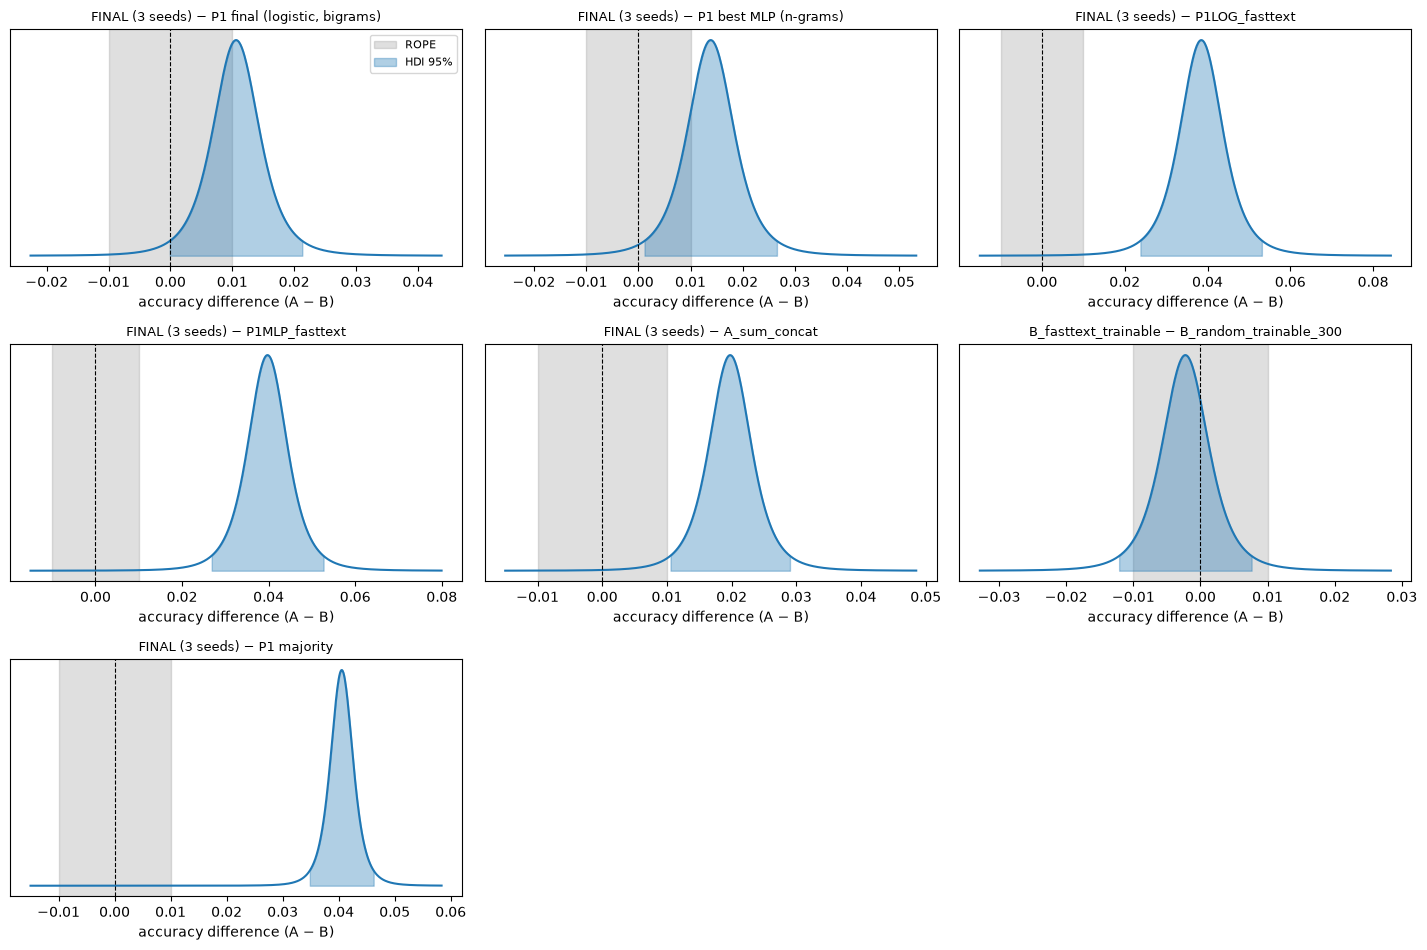

,A,B,mean_diff,HDI95_low,HDI95_high,P(A better),P(ROPE),P(B better),decision
0,FINAL (3 seeds),"P1 final (logistic, bigrams)",0.011,-0.000,0.021,0.559,0.438,0.003,undecided
1,FINAL (3 seeds),P1 best MLP (n-grams),0.014,0.001,0.027,0.777,0.219,0.003,undecided
2,FINAL (3 seeds),P1LOG_fasttext,0.038,0.024,0.053,0.997,0.003,0.000,FINAL (3 seeds) better
3,FINAL (3 seeds),P1MLP_fasttext,0.040,0.027,0.053,0.998,0.001,0.000,FINAL (3 seeds) better
4,FINAL (3 seeds),A_sum_concat,0.020,0.010,0.029,0.978,0.021,0.000,FINAL (3 seeds) better
5,B_fasttext_trainable,B_random_trainable_300,-0.002,-0.012,0.008,0.013,0.940,0.047,undecided
6,FINAL (3 seeds),P1 majority,0.041,0.035,0.046,1.000,0.000,0.000,FINAL (3 seeds) better


In [14]:
# Load from disk everything this section needs (no training)
BEST_A = "A_sum_concat"          # best stage A configuration (section 5)
FINAL = "C_hidden_256"           # final configuration (section 8)

def load_scores(name):
    with (RESULTS / name / "cv.pkl").open("rb") as f:
        res = pickle.load(f)
    SCORES[name], PREDS[name] = pd.Series(dict(res["accuracies"])), res["predictions"]

for n in [BEST_A, "B_fasttext_trainable", "B_random_trainable_300", "P1MLP_fasttext",
          FINAL, f"{FINAL}_seed1", f"{FINAL}_seed2"]:
    load_scores(n)
SCORES["FINAL (3 seeds)"] = pd.concat(
    [SCORES[n] for n in [FINAL, f"{FINAL}_seed1", f"{FINAL}_seed2"]], axis=1).mean(axis=1)

assert "P1LOG_fasttext" in SCORES, "Run the cell of section 6.2 first (about 1 minute)"

final_rows = ["P1 majority", "P1 final (logistic, bigrams)", "P1 best MLP (n-grams)",
              "P1LOG_fasttext", "P1MLP_fasttext",
              BEST_A, "B_fasttext_trainable", "B_random_trainable_300", "FINAL (3 seeds)"]

overview = pd.DataFrame({
    "acc mean": [SCORES[n].mean() for n in final_rows],
    "acc std (folds)": [SCORES[n].std() for n in final_rows],
}, index=final_rows)
display(save_table(overview, TABLES / "final_overview.csv").style.format(precision=4, na_rep=""))

display(compare([
    ("FINAL (3 seeds)", "P1 final (logistic, bigrams)"),
    ("FINAL (3 seeds)", "P1 best MLP (n-grams)"),
    ("FINAL (3 seeds)", "P1LOG_fasttext"),
    ("FINAL (3 seeds)", "P1MLP_fasttext"),
    ("FINAL (3 seeds)", BEST_A),                              # trainable vs frozen fastText
    ("B_fasttext_trainable", "B_random_trainable_300"),       # same model, with vs without pretraining
    ("FINAL (3 seeds)", "P1 majority"),
], save_as="final_bayes", plot=True))


In [11]:
from sklearn.metrics import f1_score, recall_score

FINAL = "C_hidden_256"   # final configuration (section 8)

# Load the predictions of the final model (3 seeds) from disk if they are not in memory
for n in [FINAL, f"{FINAL}_seed1", f"{FINAL}_seed2"]:
    if n not in PREDS:
        with (RESULTS / n / "cv.pkl").open("rb") as f:
            PREDS[n] = pickle.load(f)["predictions"]


def classification_metrics(name):
    rows = []
    for fold in folds:
        y_true = np.array([y for _, y in fold_ids[fold]["validation"]])
        y_pred = np.asarray(PREDS[name][fold])
        rows.append({
            "accuracy": np.mean(y_true == y_pred),
            "macro-F1": f1_score(y_true, y_pred, average="macro"),
            "paraphrase recall": recall_score(y_true, y_pred, pos_label=1),
            "predicted paraphrase rate": np.mean(y_pred == 1),
        })
    return pd.DataFrame(rows).mean()


models = {
    "Part 1 Logistic": ["P1 final (logistic, bigrams)"],
    "Part 1 MLP": ["P1 best MLP (n-grams)"],
    "Final Embed-and-Pool": [FINAL, f"{FINAL}_seed1", f"{FINAL}_seed2"],
}

results = {}
for label, names in models.items():
    results[label] = pd.concat([classification_metrics(n) for n in names], axis=1).mean(axis=1)

metrics_table = pd.DataFrame(results).T
display(save_table(metrics_table, TABLES / "final_class_metrics.csv").round(4))


,accuracy,macro-F1,paraphrase recall,predicted paraphrase rate
Part 1 Logistic,0.5881,0.4896,0.1683,0.1188
Part 1 MLP,0.5849,0.4873,0.1701,0.1236
Final Embed-and-Pool,0.5988,0.4725,0.1243,0.0693


**Final comparison** : The selected three-seed Embed-and-Pool configuration achieves 59.88% mean accuracy, compared with 58.81% for Part 1 logistic regression and 58.49% for the Part 1 MLP. The paired Bayesian comparisons are undecided for both Part 1 systems under our ±1-point ROPE (posterior probabilities of a practically meaningful advantage: approximately 0.559 and 0.777, respectively). Thus, the new system has a higher observed CV accuracy, but its practical superiority is not statistically established by this analysis.

The selected model also outperforms the frozen pooled-feature logistic and MLP controls by about 3.8–4.0 percentage points, and it is about 2.0 points above the frozen fastText configuration selected in Stage A. These comparisons change several aspects of the system simultaneously, so they should be interpreted as end-to-end system comparisons, not as isolated measures of pretraining or fine-tuning.

### 10.1 Performance Across Lexical-Overlap Groups

As a brief diagnostic, we group validation pairs by whether the two sentences contain the same multiset of token IDs or, otherwise, by low, medium, or high token-set Jaccard overlap. We compare the selected Embed-and-Pool classifier (seed 0) against the Part 1 MLP within each group. This complements the main comparison without attempting a full error analysis, which belongs to Exercise 6.

The final model obtains 60.8% accuracy on low-overlap pairs, 55.8% on medium-overlap pairs, 59.0% on high-overlap pairs, and 79.5% on same-bag pairs, compared with 59.1%, 54.8%, 57.9%, and 76.6% for the Part 1 MLP. The same-bag group has a relatively low paraphrase rate (26.7%), so high accuracy in that group must not be interpreted as evidence that the pooled model understands word order. When sentence vectors are identical, the model cannot recover the original ordering.

In [15]:
rows = []
for fold, split in folds.items():
    for j, ((a, b), y) in enumerate(fold_ids[fold]["validation"]):
        sa, sb = set(a), set(b)
        rows.append({
            "fold": fold, "label": y,
            "same_bag": sorted(a) == sorted(b),
            "jaccard": len(sa & sb) / max(len(sa | sb), 1),
            "embed_pool": PREDS[FINAL][fold][j],
            "part1_mlp": PREDS["P1 best MLP (n-grams)"][fold][j],
        })
val = pd.DataFrame(rows)
val["group"] = np.where(val["same_bag"], "same bag of words",
                        "jaccard " + pd.qcut(val["jaccard"].where(~val["same_bag"]), 3,
                                             labels=["low", "mid", "high"]).astype(str))

def group_stats(g):
    return pd.Series({
        "pairs": len(g),
        "paraphrase rate": g["label"].mean(),
        "majority acc": max(g["label"].mean(), 1 - g["label"].mean()),
        "embed-and-pool acc": (g["embed_pool"] == g["label"]).mean(),
        "Part 1 MLP acc": (g["part1_mlp"] == g["label"]).mean(),
        "embed-and-pool predicts paraphrase": g["embed_pool"].mean(),
        "Part 1 MLP predicts paraphrase": g["part1_mlp"].mean(),
    })

by_group = val.groupby("group").apply(group_stats)
display(save_table(by_group, TABLES / "accuracy_by_overlap.csv").style.format(precision=3))

,pairs,paraphrase rate,majority acc,embed-and-pool acc,Part 1 MLP acc,embed-and-pool predicts paraphrase,Part 1 MLP predicts paraphrase
group,,,,,,,
jaccard high,14541.000,0.460,0.540,0.590,0.579,0.081,0.132
jaccard low,15600.000,0.421,0.579,0.608,0.591,0.064,0.116
jaccard mid,15990.000,0.481,0.519,0.558,0.548,0.071,0.130
same bag of words,3207.000,0.267,0.733,0.795,0.766,0.086,0.088


## 11. Conclusions

**Which design choices matter?** In Stage A, sum pooling with concatenation provides the highest mean accuracy (57.90%), but differences from the nearest alternatives are practically negligible under a ±1-point ROPE. Stage B shows a larger effect from training the embedding layer: frozen fastText reaches 57.90%, whereas trainable fastText reaches 59.55%. In Stage C, a nonlinear MLP is substantially better in accuracy than a linear classifier on concatenated sentence vectors (59.87% versus 54.70%). Increasing MLP width or depth beyond the 128-unit reference has much smaller effects. Stage D finds that the original learning rate (1e-3) and batch size (64) perform best among the settings tested, although changing batch size produces no practically meaningful difference.

**Did pretrained embeddings add to the design?** The evidence is not clearly in favor of pretraining. When both sets of embeddings are trainable, randomly initialized embeddings achieve 59.78%, slightly above fastText's 59.55%; their difference is practically equivalent under the Bayesian comparison (ROPE probability 0.940). Fixed fastText embeddings modestly outperform fixed random embeddings, but replacing Part 1 n-gram inputs with fixed pooled fastText or GloVe features reduces the accuracy of the reused MLP. The results suggest that task-specific learning of embeddings matters more than pretrained initialization in the configurations evaluated here.

**Is Embed-and-Pool better than Part 1?** The final configuration uses trainable, randomly initialized 300d embeddings, sum pooling, concatenated sentence vectors, and a one-hidden-layer MLP with 256 ReLU units (dropout 0.1, Adam learning rate 1e-3, batch size 64). Averaged across three seeds and five folds, it reaches 59.88% accuracy versus 58.81% for the previous bigram logistic model and 58.49% for the previous n-gram MLP. These are observed gains of 1.07 and 1.39 percentage points, respectively. However, the Bayesian comparisons with both Part 1 systems are undecided under the ±1-point ROPE, so we cannot claim a conclusive practical improvement. The earlier n-gram classifiers also outperform the fixed pooled-feature MLP and logistic controls.

**Limitations**. Mean and sum pooling discard word order, a major limitation for PAWS. The staged search and final comparison reuse the same folds, which may make the selected CV accuracy optimistic. Most ablations use only one seed, and dimensionality was studied through PCA compression rather than training independent embedding spaces of different sizes. A final evaluation on independent held-out data would be needed to confirm generalization.

Overall, Embed-and-Pool is a competitive lightweight baseline for PAWS, but the results do not demonstrate that pretrained word embeddings themselves provide a clear advantage over learning embeddings for this task.